# Project 2 — Ranking transactions for fraud investigation
**DSC8307: Data Mining, Modeling and Analytics | Advent 2026**

## Problem formulation and evaluation contract
Produce a ranking for a limited investigation queue, not an automatic accusation of fraud. Compare a statistical robust-z baseline, a K-means distance detector (cluster based), and a one-class SVM (classification based). One-class classification learns a boundary around predominantly normal transactions without fraud labels. This satisfies label-withheld anomaly detection; a supervised fraud classifier would answer a different training question.

**Leakage controls:** remove repeated feature records while preserving the earliest transaction, sort by elapsed Time, split at time quantiles into approximately 60% training, 20% validation and 20% final test. Fit preprocessing and detectors on training features alone. Validation labels are used only to report sensitivity; the main settings are fixed in advance (K=32; RBF one-class SVM nu=.01, gamma='scale'). Test labels are accessed only for final evaluation. No resampling by Class, label-based feature selection, contamination calibration from labels, or test-driven tuning.

Primary metrics: average precision (AP), precision and recall at a 0.5% investigation budget; ROC-AUC is secondary because legitimate transactions dominate. Fraud prevalence is the conventional random-ranking precision–recall reference; finite-sample random AP need not equal it exactly. Report fixed validation-score thresholds separately from exact test queue budgets.

**Data access:** The first run downloads the public benchmark data using `download_data.py`. The helper verifies the assignment data checksum before analysis. Internet access is required on the first run; subsequent runs use cached files. Raw data and individual customer/transaction exports are excluded from Git; published outputs contain aggregate tables and figures.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=2)
SEED = 8307
rng = np.random.default_rng(SEED)
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': .2})
from download_data import ensure_data
DATA = Path('data')
OUT = Path('results'); OUT.mkdir(exist_ok=True)
print({'python':platform.python_version(), 'numpy':np.__version__, 'pandas':pd.__version__, 'sklearn':sklearn.__version__})
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.svm import OneClassSVM
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, confusion_matrix
path=ensure_data('creditcard', DATA)
df=pd.read_csv(path)
print('SHA256:',hashlib.sha256(path.read_bytes()).hexdigest())
print('Shape:',df.shape,'missing:',int(df.isna().sum().sum()),'exact duplicates:',int(df.duplicated().sum()))
display(df[['Time','Amount','Class']].describe().T)
display(df.Class.value_counts().to_frame('transactions'))
assert df.shape==(284807,31) and df.isna().sum().sum()==0
assert set(df.Class.unique())=={0,1} and (df.Amount>=0).all()
print(f'Fraud prevalence: {df.Class.mean():.6%}; majority-rule accuracy: {1-df.Class.mean():.6%}')


{'python': '3.12.13', 'numpy': '2.5.4', 'pandas': '3.1.1', 'sklearn': '1.9.1'}


SHA256: 76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89


Shape: (284807, 31) missing: 0 exact duplicates: 1081


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16
Class,284807.0,0.001727,0.041527,0.0,0.0,0.0,0.000,1.00


,transactions
Class,
0,284315
1,492


Fraud prevalence: 0.172749%; majority-rule accuracy: 99.827251%


## Exploration, limitations and preparation
V1…V28 are anonymized PCA components; Time is elapsed seconds and Amount is EUR. Inspect component tails, amount skew and hourly transaction volume. There are only two days, no customer identifiers, merchant context or demographics. The original PCA was supplied already fitted: its construction history is unknown and any full-dataset preprocessing in its creation cannot be undone. Our additional transforms use only training data.

Deduplicate identical full recorded patterns (all columns except Class, including Time) without consulting Class, retaining the first occurrence. This removes duplicate records, while similar model-input vectors at different times may remain; customer-level independence cannot be guaranteed. This may merge genuinely distinct identical purchases, so the resulting estimand is unique full recorded patterns rather than all production transactions. Report removed records and split counts explicitly. Exclude Time from distance inputs: raw elapsed time largely encodes collection order and would make later transactions mechanically unusual. Use it for splitting and drift diagnostics. Apply `log1p(Amount)` and robust scaling to every input (training medians and IQRs); do not truncate tails, since extremes are the intended signal.

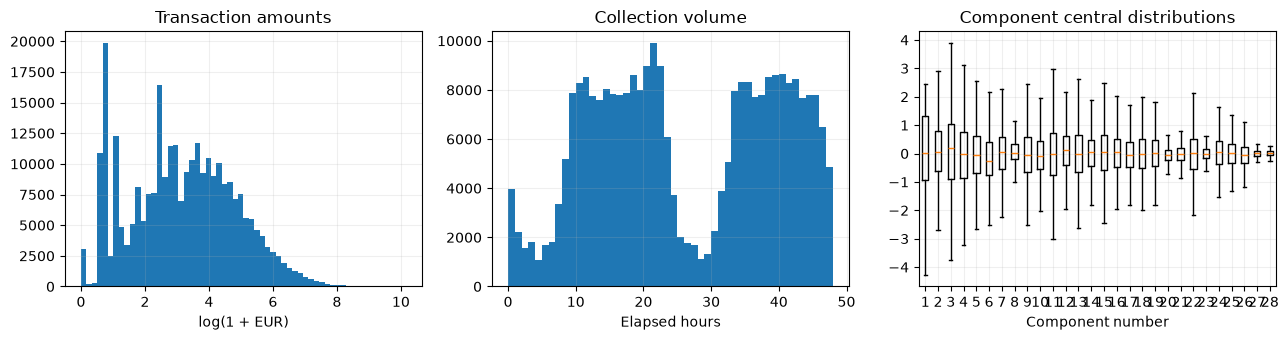

,absolute_skew
Amount,16.977724
V28,11.192091
V8,8.521944
V23,5.875140
V2,4.624866
V17,3.844914
V21,3.592991
V1,3.280667
V7,2.553907
V5,2.425901


Repeated feature records removed: 1081


,split,rows,start_time,end_time
0,train,170236,0.0,120393.0
1,validation,56746,120394.0,145234.0
2,test,56744,145235.0,172792.0


In [2]:
fig,ax=plt.subplots(1,3,figsize=(13,3.5))
ax[0].hist(np.log1p(df.Amount),bins=60); ax[0].set(xlabel='log(1 + EUR)',title='Transaction amounts')
ax[1].hist(df.Time/3600,bins=48); ax[1].set(xlabel='Elapsed hours',title='Collection volume')
ax[2].boxplot(df[[f'V{i}' for i in range(1,29)]].to_numpy(),showfliers=False); ax[2].set(title='Component central distributions',xlabel='Component number')
plt.tight_layout(); plt.show()
display(df.drop(columns='Class').skew().abs().sort_values(ascending=False).head(10).to_frame('absolute_skew'))
feature_cols=[c for c in df.columns if c!='Class']
clean=df.sort_values('Time',kind='stable').drop_duplicates(subset=feature_cols,keep='first').reset_index(drop=True)
print('Repeated feature records removed:',len(df)-len(clean))
t1,t2=clean.Time.quantile([.6,.8]).to_numpy()
parts=[clean.loc[clean.Time<=t1].copy(),clean.loc[(clean.Time>t1)&(clean.Time<=t2)].copy(),clean.loc[clean.Time>t2].copy()]
train,val,test=parts
assert train.Time.max()<val.Time.min() and val.Time.max()<test.Time.min()
display(pd.DataFrame([{'split':name,'rows':len(part),'start_time':part.Time.min(),'end_time':part.Time.max()} for name,part in zip(['train','validation','test'],parts)]))
inputs=[f'V{i}' for i in range(1,29)]+['Amount']
def make_features(frame):
    A=frame[inputs].copy(); A['Amount']=np.log1p(A.Amount); return A
scaler=RobustScaler().fit(make_features(train))
Atrain=scaler.transform(make_features(train)); Aval=scaler.transform(make_features(val)); Atest=scaler.transform(make_features(test))
assert np.isfinite(Atrain).all() and np.isfinite(Atest).all()
# Numerical feature-only assertions: Class never appears in detector inputs.
assert 'Class' not in inputs and Atrain.shape[1]==29


## Statistical outlier baseline
For each feature compute the absolute modified z-score: 0.67448975 × |x − training median| / training MAD. Rank by the maximum across 29 features. Replace zero MAD by 1 only as a numerical safeguard and report the count. A conventional threshold of 3.5 flags statistical extremes; its multiple-feature alert rate can be large, so also evaluate ranking and a capacity-based threshold. Heavy tails, correlations and unknown marginal distributions undermine a literal Gaussian interpretation: this baseline is a transparent heuristic, not a fraud probability.

In [3]:
center=np.median(Atrain,axis=0); mad=np.median(np.abs(Atrain-center),axis=0)
print('Zero-MAD columns:',int((mad==0).sum()))
mad=np.where(mad>0,mad,1.)
def robust_score(A): return np.max(.67448975*np.abs(A-center)/mad,axis=1)
scores_val={'Robust z':robust_score(Aval)}
scores_test={'Robust z':robust_score(Atest)}
print('Validation statistical-outlier rate at 3.5:',np.mean(scores_val['Robust z']>3.5))


Zero-MAD columns: 0
Validation statistical-outlier rate at 3.5: 0.3274944489479435


## Cluster-based detector and one-class classifier
**Cluster distance:** MiniBatchKMeans gives scalable prototypes of the dominant transaction patterns. Score each transaction by its Euclidean distance to its nearest center, divided by that training cluster's median radius. This prevents naturally broad clusters from dominating every alert. The radius floor is numerical only. Rare compact fraud patterns could form their own cluster and escape detection; this is a limitation of geometric anomaly detection.

**One-class SVM:** an RBF boundary accommodates nonlinear normal regions. Large negative decision_function values indicate stronger anomalies. Exact kernel training has high computational cost, so draw a fixed random 12,000-row training subset without labels; score all held-out rows in batches. The mixture is assumed overwhelmingly legitimate, but contamination can distort the learned boundary. `nu` controls a training boundary tradeoff, not the real fraud prevalence or the investigation budget. A one-class classifier needs no synthetic fraud labels.

In [4]:
def fit_cluster(k,seed=SEED):
    model=MiniBatchKMeans(n_clusters=k,batch_size=4096,n_init=10,random_state=seed).fit(Atrain)
    group=model.predict(Atrain)
    distance=np.linalg.norm(Atrain-model.cluster_centers_[group],axis=1)
    radii=np.array([np.median(distance[group==j]) if np.any(group==j) else np.median(distance) for j in range(k)])
    radii=np.maximum(radii,1e-8)
    def score(A):
        g=model.predict(A)
        return np.linalg.norm(A-model.cluster_centers_[g],axis=1)/radii[g]
    return model,score
km,cluster_score=fit_cluster(32)
scores_val['Cluster distance']=cluster_score(Aval)
scores_test['Cluster distance']=cluster_score(Atest)
svm_ix=np.random.default_rng(SEED).choice(len(Atrain),min(12000,len(Atrain)),replace=False)
svm=OneClassSVM(kernel='rbf',gamma='scale',nu=.01,cache_size=512).fit(Atrain[svm_ix])
def svm_score(model,A):
    return np.concatenate([-model.decision_function(A[i:i+4096]).ravel() for i in range(0,len(A),4096)])
scores_val['One-class SVM']=svm_score(svm,Aval)
scores_test['One-class SVM']=svm_score(svm,Atest)
print('Models fitted without Class. Training rows:',len(Atrain),'SVM fitting rows:',len(svm_ix))


Models fitted without Class. Training rows: 170236 SVM fitting rows: 12000


## Withheld-label evaluation and validation sensitivity
Now unlock labels for evaluation only. AP is the recall-increment-weighted precision, not trapezoidal PR-AUC. A random ranking's expected precision at a queue budget is the split's prevalence. Stable row order resolves tied scores, a caveat especially for saturated SVM scores. A fixed queue guarantees workload; a fixed validation quantile threshold can exceed capacity when distributions drift. Neither is an optimized F1 threshold.

Sensitivity uses validation data for K=16,32,64 and nu=.005,.01,.02. The prespecified models remain the final-test comparison regardless of these values. Do not select a new test winner based on a favorable grid cell.

In [5]:
def evaluate(y,s,budget=.005):
    y=np.asarray(y,dtype=int); count=max(1,int(np.ceil(budget*len(y))))
    top=np.argsort(-s,kind='stable')[:count]; found=int(y[top].sum())
    return {'AP':average_precision_score(y,s),'ROC_AUC':roc_auc_score(y,s), 'queue':count,'TP':found,'FP':count-found,
            'precision_at_budget':found/count,'recall_at_budget':found/y.sum(),'lift':(found/count)/y.mean()}
yval=val.Class.to_numpy(); ytest=test.Class.to_numpy()
display(pd.DataFrame([{'split':name,'frauds':int(p.Class.sum()),'prevalence':p.Class.mean()} for name,p in zip(['train','validation','test'],parts)]))
validation=pd.DataFrame({name:evaluate(yval,s) for name,s in scores_val.items()}).T
display(validation.round(4))
sensitivity=[]
for k2 in [16,32,64]:
    if k2==32: s=scores_val['Cluster distance']
    else:
        _,f=fit_cluster(k2); s=f(Aval)
    sensitivity.append({'method':f'Cluster k={k2}',**evaluate(yval,s)})
for nu in [.005,.01,.02]:
    if nu==.01: s=scores_val['One-class SVM']
    else:
        model=OneClassSVM(nu=nu,gamma='scale',cache_size=512).fit(Atrain[svm_ix]); s=svm_score(model,Aval)
    sensitivity.append({'method':f'One-class nu={nu}',**evaluate(yval,s)})
display(pd.DataFrame(sensitivity).set_index('method').round(4))
final=pd.DataFrame({name:evaluate(ytest,s) for name,s in scores_test.items()}).T
display(final.round(4)); final.to_csv(OUT/'fraud_test_metrics.csv')
print('Random-ranking prevalence reference:',round(ytest.mean(),6))

validation.to_csv(OUT/'fraud_validation_metrics.csv')
pd.DataFrame(sensitivity).to_csv(OUT/'fraud_validation_sensitivity.csv',index=False)


,split,frauds,prevalence
0,train,342,0.002009
1,validation,57,0.001004
2,test,74,0.001304


,AP,ROC_AUC,queue,TP,FP,precision_at_budget,recall_at_budget,lift
Robust z,0.0085,0.9090,284.0,0.0,284.0,0.0000,0.0000,0.0000
Cluster distance,0.0281,0.6968,284.0,16.0,268.0,0.0563,0.2807,56.0870
One-class SVM,0.0190,0.9273,284.0,2.0,282.0,0.0070,0.0351,7.0109


,AP,ROC_AUC,queue,TP,FP,precision_at_budget,recall_at_budget,lift
method,,,,,,,,
Cluster k=16,0.0202,0.9234,284,7,277,0.0246,0.1228,24.5381
Cluster k=32,0.0281,0.6968,284,16,268,0.0563,0.2807,56.0870
Cluster k=64,0.0895,0.9088,284,28,256,0.0986,0.4912,98.1522
One-class nu=0.005,0.0190,0.9273,284,2,282,0.0070,0.0351,7.0109
One-class nu=0.01,0.0190,0.9273,284,2,282,0.0070,0.0351,7.0109
One-class nu=0.02,0.0190,0.9273,284,2,282,0.0070,0.0351,7.0109


,AP,ROC_AUC,queue,TP,FP,precision_at_budget,recall_at_budget,lift
Robust z,0.0146,0.9309,284.0,1.0,283.0,0.0035,0.0135,2.7000
Cluster distance,0.0393,0.7076,284.0,26.0,258.0,0.0915,0.3514,70.2010
One-class SVM,0.0387,0.9291,284.0,13.0,271.0,0.0458,0.1757,35.1005


Random-ranking prevalence reference: 0.001304


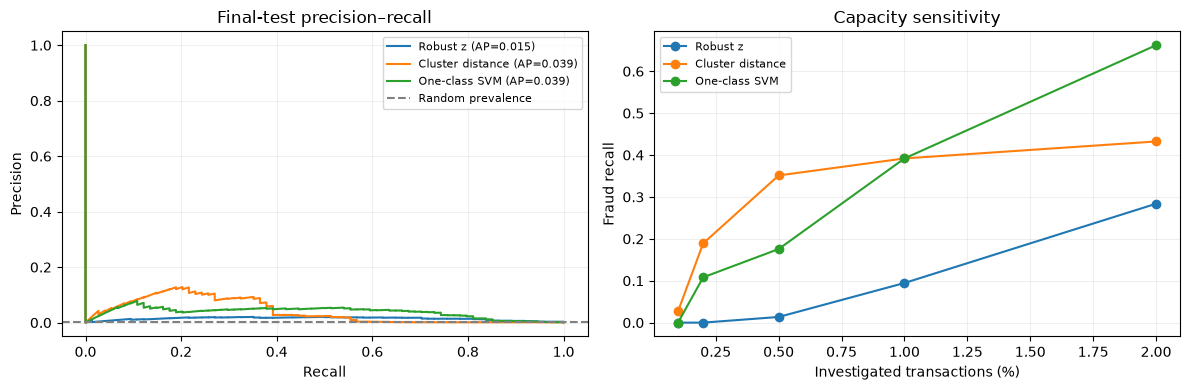

,threshold_from_validation,test_alert_rate,TN,FP,FN,TP,precision,recall
model,,,,,,,,
Robust z,39.9499,0.0027,56518,152,73,1,0.0065,0.0135
Cluster distance,3.4701,0.0029,56525,145,57,17,0.1049,0.2297
One-class SVM,0.5967,0.0025,56535,135,65,9,0.0625,0.1216


Robust-z 3.5 final-test confusion matrix [TN FP; FN TP]:
[[39458 17212]
 [    4    70]]


In [6]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
for name,s in scores_test.items():
    p,r,_=precision_recall_curve(ytest,s); ax[0].plot(r,p,label=f'{name} (AP={final.loc[name,"AP"]:.3f})')
    budgets=np.array([.001,.002,.005,.01,.02])
    recalls=[evaluate(ytest,s,b)['recall_at_budget'] for b in budgets]
    ax[1].plot(budgets*100,recalls,'o-',label=name)
ax[0].axhline(ytest.mean(),color='gray',linestyle='--',label='Random prevalence')
ax[0].set(xlabel='Recall',ylabel='Precision',title='Final-test precision–recall')
ax[1].set(xlabel='Investigated transactions (%)',ylabel='Fraud recall',title='Capacity sensitivity')
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()
threshold_rows=[]
for name,s in scores_test.items():
    threshold=float(np.quantile(scores_val[name],.995))
    pred=s>threshold; tn,fp,fn,tp=confusion_matrix(ytest,pred,labels=[0,1]).ravel()
    threshold_rows.append({'model':name,'threshold_from_validation':threshold,'test_alert_rate':pred.mean(),'TN':tn,'FP':fp,'FN':fn,'TP':tp,'precision':tp/max(tp+fp,1),'recall':tp/max(tp+fn,1)})
display(pd.DataFrame(threshold_rows).set_index('model').round(4))
# Transparent statistical-threshold result, separate from budget calibration.
pred=scores_test['Robust z']>3.5
print('Robust-z 3.5 final-test confusion matrix [TN FP; FN TP]:')
print(confusion_matrix(ytest,pred,labels=[0,1]))

pd.DataFrame(threshold_rows).to_csv(OUT/'fraud_fixed_thresholds.csv',index=False)


## Robustness, drift and uncertainty
Report AP for four successive test-time blocks and a paired bootstrap difference between SVM and clustering. The 200-resample percentile interval is descriptive: transactions may be dependent, so row bootstrap can understate uncertainty. Block metrics expose some temporal variation but only two days cannot establish generalization across weeks or customers. No identities are available for customer-group validation. Report ties and unseen score distribution shifts as diagnostics.

In [7]:
block_rows=[]
for j,ix in enumerate(np.array_split(np.arange(len(test)),4)):
    for name,s in scores_test.items():
        block_rows.append({'block':j+1,'model':name,'n':len(ix),'frauds':int(ytest[ix].sum()),'AP':average_precision_score(ytest[ix],s[ix]) if ytest[ix].sum() else np.nan})
display(pd.DataFrame(block_rows).pivot(index='block',columns='model',values='AP').round(4))
r=np.random.default_rng(SEED); deltas=[]
for _ in range(200):
    ix=r.integers(0,len(ytest),len(ytest))
    if ytest[ix].sum(): deltas.append(average_precision_score(ytest[ix],scores_test['One-class SVM'][ix])-average_precision_score(ytest[ix],scores_test['Cluster distance'][ix]))
print('SVM minus cluster AP: paired row-bootstrap 95% interval:',np.quantile(deltas,[.025,.975]))
for name,s in scores_test.items():
    print(name,'unique test scores:',len(np.unique(s)),'/',len(s),'validation median:',round(np.median(scores_val[name]),4),'test median:',round(np.median(s),4))
# Amount distributions of false positives vs captured fraud at prespecified capacity.
error_rows=[]
for name,s in scores_test.items():
    ix=np.argsort(-s,kind='stable')[:int(np.ceil(.005*len(s)))]; q=test.iloc[ix]
    for value,title in [(0,'Legitimate alerts'),(1,'Fraud alerts')]:
        a=q.loc[q.Class==value,'Amount']
        error_rows.append({'model':name,'group':title,'count':len(a),'median_EUR':a.median(),'max_EUR':a.max()})
display(pd.DataFrame(error_rows))
# Export a research ranking using only row reference, time, amount and score; no invented customer identity.
ranking=test[['Time','Amount']].copy(); ranking['source_clean_row']=test.index
for name,s in scores_test.items(): ranking[name]=s
ranking.to_csv(OUT/'fraud_test_rankings.csv',index=False)
winner=final.AP.idxmax()
display(Markdown(f"""## Findings from the executed experiment
The highest final-test AP among the prespecified methods is **{winner}**, with AP **{final.loc[winner,'AP']:.4f}** against prevalence reference **{ytest.mean():.4f}**. At a 0.5% queue, it captures **{int(final.loc[winner,'TP'])}** frauds with **{int(final.loc[winner,'FP'])}** legitimate alerts (precision **{final.loc[winner,'precision_at_budget']:.1%}**, recall **{final.loc[winner,'recall_at_budget']:.1%}**). This is a retrospective comparison, not an unbiased estimate of a winner selected on test data. For deployment, select a policy on a separate validation period and audit it on a new future period.

The tables and capacity curves show whether a method's global ranking advantage also helps at the operational budget. A detector can have attractive ROC-AUC and still generate many false investigations. Threshold alert rates should be compared with capacity rather than assumed to remain 0.5%."""))


model,Cluster distance,One-class SVM,Robust z
block,,,
1,0.0499,0.0315,0.0152
2,0.0640,0.1000,0.0367
3,0.0094,0.0558,0.0131
4,0.0619,0.0137,0.0066


SVM minus cluster AP: paired row-bootstrap 95% interval: [-0.02238768  0.01779479]
Robust z unique test scores: 55512 / 56744 validation median: 2.8408 test median: 2.7497
Cluster distance unique test scores: 55550 / 56744 validation median: 1.2272 test median: 1.2043
One-class SVM unique test scores: 55533 / 56744 validation median: -0.391 test median: -0.4084


,model,group,count,median_EUR,max_EUR
0,Robust z,Legitimate alerts,283,44.300,25691.16
1,Robust z,Fraud alerts,1,12.310,12.31
2,Cluster distance,Legitimate alerts,258,38.195,25691.16
3,Cluster distance,Fraud alerts,26,1.385,390.00
4,One-class SVM,Legitimate alerts,271,127.900,25691.16
5,One-class SVM,Fraud alerts,13,1.100,296.00


## Findings from the executed experiment
The highest final-test AP among the prespecified methods is **Cluster distance**, with AP **0.0393** against prevalence reference **0.0013**. At a 0.5% queue, it captures **26** frauds with **258** legitimate alerts (precision **9.2%**, recall **35.1%**). This is a retrospective comparison, not an unbiased estimate of a winner selected on test data. For deployment, select a policy on a separate validation period and audit it on a new future period.

The tables and capacity curves show whether a method's global ranking advantage also helps at the operational budget. A detector can have attractive ROC-AUC and still generate many false investigations. Threshold alert rates should be compared with capacity rather than assumed to remain 0.5%.

## What the results support, and what they do not
At the prespecified 0.5% queue, clustering yields **9.15% precision and 35.14% recall**, versus **4.58% precision and 17.57% recall** for the SVM. This roughly doubles captured fraud at equal workload, yet **90.85% of cluster alerts are legitimate**. The cluster detector's ROC-AUC (**0.708**) is worse than the SVM's (**0.929**), illustrating why global ROC-AUC alone would select poorly for this small queue. Their AP values are close (**0.0393 vs 0.0387**); the paired bootstrap interval for SVM minus cluster AP (**−0.0224 to +0.0178**) spans zero. There is insufficient evidence for a reliable AP advantage, and time-block AP changes substantially.

The robust-z 3.5 rule captures **70 of 74 frauds** but flags **17,212 legitimate transactions** (over 30% of the test period). That workload makes it unsuitable for the assumed queue. Its top-ranked 0.5% queue captures only one fraud: the most extreme marginal values are mostly legitimate. Moderate statistical extremeness and fraud-risk ranking are different objectives.

The validation grid is consequential: K=64 improves validation AP to **0.0895**, compared with **0.0281** for the fixed K=32 reference. K=32 is a prespecified moderate prototype count balancing broad transaction modes against small-cluster fragmentation, not an empirically optimal claim. The favorable K=64 validation result motivates a future validation-selected detector assessed on a **new** holdout; its performance is not quietly substituted into the already opened test comparison. SVM nu changes produce nearly identical validation ranking metrics in this grid, so nu tuning alone has not addressed its limitations; gamma, feature weighting and training-subset variability remain untested.

Training, validation and test prevalence differ (**0.201%, 0.100%, 0.130%**). The chronological design is more realistic for later transactions than a random split but leaves few fraud events in each evaluation period. Fixed validation thresholds yield roughly **0.25–0.29%** test alerts rather than the calibrated 0.5%, evidence that an operating threshold is not stable across periods. For a strict capacity constraint, rank the current queue; for real-time use, recalibrate and monitor volumes with a separate capacity policy. Neither the two-day sample nor the row bootstrap establishes long-term reliability.

The deduplicated test set answers a narrower question than all recorded transactions, and changing that data policy could change the findings. The original file contains 492 fraud records; deduplicated splits contain 473. No dropped records are secretly used for fitting or evaluation. An all-record sensitivity analysis and customer-group validation would be appropriate extensions if repeated-event provenance and identities became available.

## Why unusual does not mean fraudulent
A legitimate one-off expensive purchase, travel, a new merchant or a change in shopping habits can be rare. Conversely, fraudsters can imitate common purchase amounts and transaction patterns. Geometry detects rarity in anonymized features, while fraud is an unauthorized action requiring external evidence. The legitimate alerts above are an empirical demonstration of that distinction. These scores are not calibrated fraud probabilities.

Use the ranking as human-review triage with proportionate authentication, an appeal path, and monitoring of customer burden. Do not automatically decline or accuse on anomaly scores alone. Collect confirmed investigation outcomes while recognizing verification bias (unreviewed transactions can conceal fraud), monitor drift and retrain under a documented validation policy. Without demographic or customer-level information, fairness and repeated individual alert burden cannot be evaluated. Historical European transactions from two days in 2013 cannot establish performance in Uganda or a current payment system. Amount and missed-fraud costs matter, but no cost model was supplied; an economic optimum cannot be claimed.

## References and attribution
- Supplied `creditcard.csv` and `creditcard-README.txt`: data provenance, PCA anonymization, date and label definition. Labels are used as recorded; their verification history is unknown.
- [scikit-learn novelty/outlier guide](https://scikit-learn.org/stable/modules/outlier_detection.html): contamination assumptions and distinction between outlier and novelty detection.
- [OneClassSVM](https://scikit-learn.org/stable/modules/generated/sklearn.svm.OneClassSVM.html): decision function and nu interpretation.
- [MiniBatchKMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MiniBatchKMeans.html): scalable centroid estimation.
- [Average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html): AP definition and distinction from trapezoidal PR area.
- Iglewicz, B. and Hoaglin, D. C. (1993), *How to Detect and Handle Outliers*, ASQC Quality Press: modified z-score convention. No Gaussian false-alarm guarantee is asserted here.

**Preparation disclosure:** This analysis and code were prepared with AI assistance. The submitting student should verify all outputs, understand the methods and comply with institutional disclosure requirements.

Public download provenance: [TensorFlow imbalanced-data tutorial](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data), which references the Worldline/ULB Credit Card Fraud Detection dataset. Its public CSV is verified byte for byte against the assignment file. No transaction records or individual rankings are bundled in this repository.
